In [38]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

In [39]:
k = 1
kT = .15
N = 100000
Tij = 1/N

In [ ]:
k, kT = 1.0, 0.15
N, L = 200, 4.0
x = np.linspace(-L, L, N)
V = 0.5 * k * x**2

n_steps = 500_000
i = np.random.randint(N)            # arbitrary starting site
visits = np.zeros(N)

for _ in range(n_steps):
    j = np.random.randint(N)        # global proposal, probability 1/N
    dV = V[j] - V[i]
    if dV <= 0 or np.random.rand() < np.exp(-dV / kT):
        i = j                       # accept
    visits[i] += 1                  # record current site, even if rejected

p_sampled = visits / visits.sum()
print("<V> sampled:", np.sum(p_sampled * V))

# Check against the exact discrete Boltzmann average
w = np.exp(-V / kT)
p_exact = w / w.sum()
print("<V> exact  :", np.sum(p_exact * V))
print("equipartition kT/2:", kT / 2)

<V> sampled: 0.07617822661043913
<V> exact  : 0.07500000000000001
equipartition kT/2: 0.075


In [53]:
def V(x, k=1):
    return 0.5*k*x**2

   

N_sites = 100
x = np.linspace(-4, 4, N_sites)     
Vx = V(x)  
steps = 1_000_000
i = np.random.randint(N_sites) # Initial state
visits = np.zeros(N_sites)

for _ in range(steps):
    j = np.random.randint(N_sites)                     # Proposes new site
    dV = Vx[j] - Vx[i]                                   # Difference in potential
    if dV <= 0 or np.random.rand() < np.exp(-dV / kT): # Always accept if dV is negative or accept with random prob if not
        i = j                                          # Accept
    visits[i] += 1                                     # Counts visits, not going to a new site counts the current site again

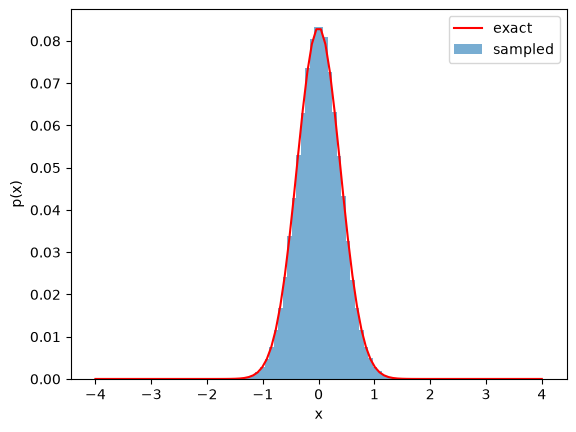

In [54]:
p = visits / visits.sum()
plt.bar(x, p, width=x[1]-x[0], alpha=0.6, label="sampled")
w = np.exp(-Vx / kT)
plt.plot(x, w / w.sum(), "r", label="exact")
plt.xlabel("x"); plt.ylabel("p(x)"); plt.legend()